In [1]:
import pandas as pd
import matplotlib.pyplot as plt

fda = pd.read_csv("../data/processed/fda_decisions.csv")
by_year = fda.groupby(["decision_year", "pathway"]).size().unstack(fill_value=0)
by_year.tail(10)

pathway,510(k),De Novo,PMA
decision_year,,,
2017,191,4,1
2018,160,4,3
2019,155,4,2
2020,155,1,1
2021,160,6,0
2022,169,2,1
2023,196,2,2
2024,189,3,1
2025,218,7,4


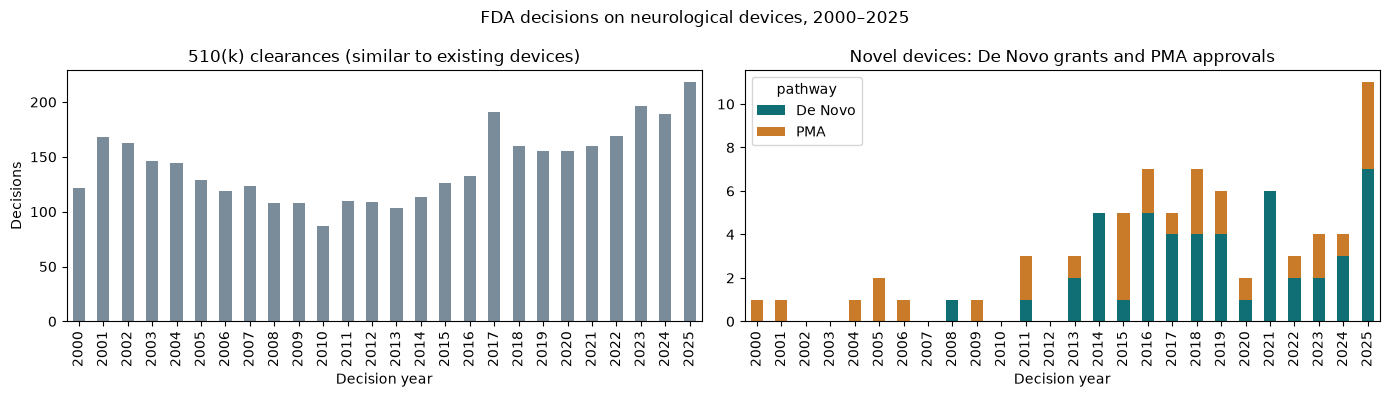

In [2]:
by_year = by_year.loc[2000:2025]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

by_year["510(k)"].plot(kind="bar", ax=ax1, color="#7a8b99")
ax1.set_title("510(k) clearances (similar to existing devices)")
ax1.set_xlabel("Decision year")
ax1.set_ylabel("Decisions")

by_year[["De Novo", "PMA"]].plot(kind="bar", stacked=True, ax=ax2, color=["#0f6f74", "#c97b2a"])
ax2.set_title("Novel devices: De Novo grants and PMA approvals")
ax2.set_xlabel("Decision year")

fig.suptitle("FDA decisions on neurological devices, 2000–2025")
plt.tight_layout()
plt.savefig("../reports/figures/fda_decisions_by_year.png", dpi=150)

In [3]:
recent = fda[fda["decision_year"] >= 2013]
recent.groupby("pathway")["review_days"].describe()[["count", "25%", "50%", "75%", "max"]].round(0)

,count,25%,50%,75%,max
pathway,,,,,
510(k),2226.0,89.0,134.0,220.0,846.0
De Novo,49.0,225.0,335.0,540.0,1520.0
PMA,23.0,300.0,423.0,634.0,1231.0


In [4]:
denovo = fda[fda["pathway"] == "De Novo"]
denovo[["decision_year", "applicant", "device_name", "review_days"]].sort_values("decision_year")

,decision_year,applicant,device_name,review_days
2028,1998,"Cranial Technologies, Inc.",DYNAMIC ORTHOTIC CRANIOPLASTY BAND; DOC BAND,59
3432,2008,Neuronetics,NEUROSTAR TMS SYSTEM,502
3672,2011,Ab Mando,MANDOMETER III,1380
3930,2013,"Lexicor Medical Technology, LLC",NEBA SYSTEM,585
3976,2013,Eneura Therapeutics,NEURALIEVE CERENA TRANSCRANIAL MAGNETIC STIMUL...,283
4004,2014,Stx-Med Sprl,CEFALY,453
4058,2014,Medtronic Neurosurgery,Medtronic DUET External Drainage and Monitorin...,609
4079,2014,"Ecobrands , Ltd.",ZAP-IT!,1520
4080,2014,Tecnimed S.R.L.,ZANZA-CLICK,617
4088,2014,"Brainscope Company, Inc.",BrainScope Ahead 100,89


In [5]:
novel = fda[fda["pathway"].isin(["De Novo", "PMA"])].copy()
novel["category"] = ""
novel["include"] = ""
novel[["submission_number", "pathway", "decision_year", "applicant", "device_name", "category", "include"]] \
    .sort_values("decision_year") \
    .to_csv("../data/processed/novel_devices_labels.csv", index=False)
print(len(novel), "novel devices exported")

95 novel devices exported
